#  Multivariate Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data.csv", encoding="cp1252")

# Convert the date column to datetime
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

# Create a feature for the recorded value of each retail line
df["LineValue"] = df["Quantity"] * df["UnitPrice"]

# Create date-based features
df["InvoiceMonth"] = df["InvoiceDate"].dt.month
df["InvoiceHour"] = df["InvoiceDate"].dt.hour

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (541909, 11)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  LineValue  \
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom      15.30   
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom      20.34   
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom      22.00   
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom      20.34   
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom      20.34   

   InvoiceMonth  InvoiceHour  
0            12            8  
1            12           

## Correlation Matrix
A correlation matrix is a table that shows the correlation between every pair of selected numerical variables.
Correlation measures the strength and direction of a linear relationship. Its values range from -1 to +1.Correlation Matrix


In [2]:
# Select numerical features for correlation analysis
numeric_features = [
    "Quantity",
    "UnitPrice",
    "LineValue",
    "InvoiceMonth",
    "InvoiceHour"
]

numeric_df = df[numeric_features].dropna()

# Calculate the correlation matrix
correlation_matrix = numeric_df.corr()

print(correlation_matrix.round(2))

              Quantity  UnitPrice  LineValue  InvoiceMonth  InvoiceHour
Quantity          1.00      -0.00       0.89         -0.00        -0.01
UnitPrice        -0.00       1.00      -0.16         -0.00         0.00
LineValue         0.89      -0.16       1.00          0.00        -0.01
InvoiceMonth     -0.00      -0.00       0.00          1.00         0.03
InvoiceHour      -0.01       0.00      -0.01          0.03         1.00


## Heatmap
A heatmap is a visual representation of a correlation matrix. Colors help us quickly identify strong positive and negative correlations.

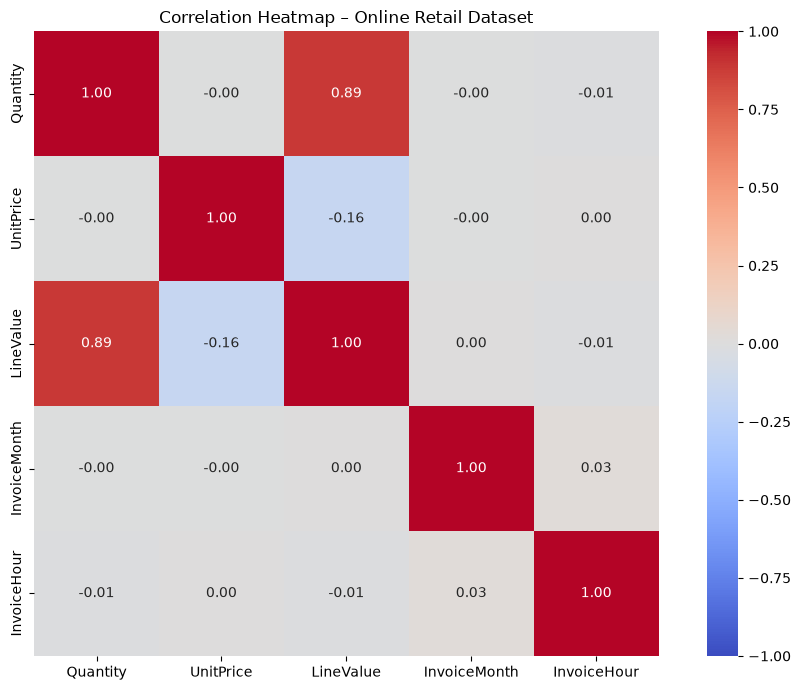

In [4]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f",
    square=True
)

plt.title("Correlation Heatmap – Online Retail Dataset")
plt.tight_layout()
plt.show()

## Pair Plot
A pair plot displays scatter plots for pairs of numerical features and distributions for individual features. It helps us inspect several relationships at once.

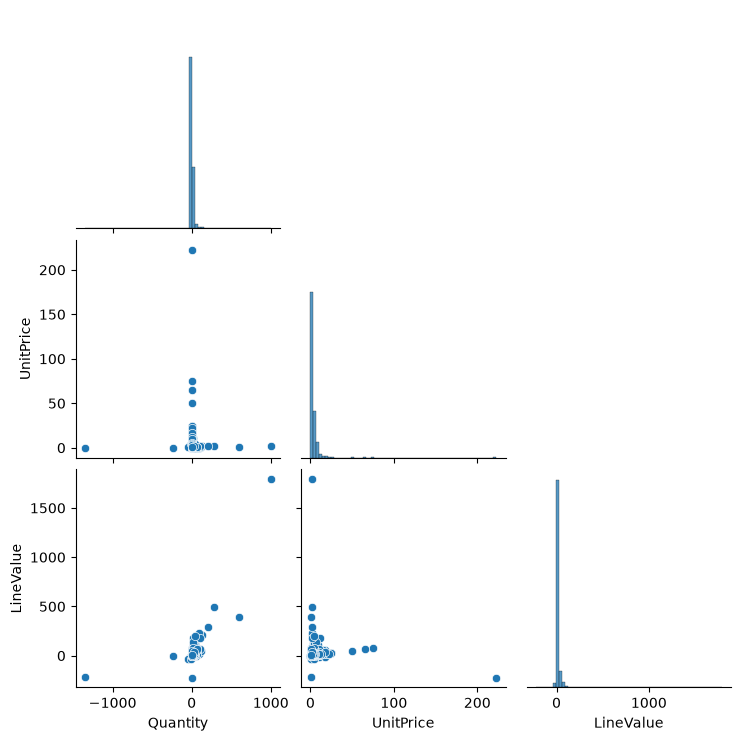

In [5]:
pair_features = [
    "Quantity",
    "UnitPrice",
    "LineValue"
]

# Use a sample to keep the visualization manageable
pair_data = df[pair_features].replace(
    [np.inf, -np.inf], np.nan
).dropna()

pair_data = pair_data.sample(
    n=min(1000, len(pair_data)),
    random_state=42
)

sns.pairplot(
    pair_data,
    diag_kind="hist",
    corner=True
)

plt.show()

## Multiple Feature Relationships
Sometimes a relationship becomes clearer when we examine several features together.
### Example,
we can compare Quantity, UnitPrice, and Country to investigate whether quantity and price patterns differ between countries.

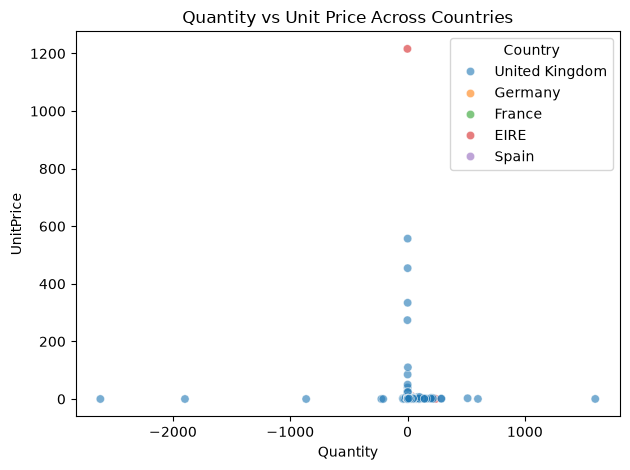

In [6]:
# Select countries with the most records
top_countries = df["Country"].value_counts().head(5).index

country_data = df[df["Country"].isin(top_countries)].copy()

# Keep a manageable sample for visualization
plot_data = country_data[
    ["Quantity", "UnitPrice", "Country"]
].replace([np.inf, -np.inf], np.nan).dropna()

plot_data = plot_data.sample(
    n=min(3000, len(plot_data)),
    random_state=42
)

sns.scatterplot(
    data=plot_data,
    x="Quantity",
    y="UnitPrice",
    hue="Country",
    alpha=0.6
)

plt.title("Quantity vs Unit Price Across Countries")
plt.tight_layout()
plt.show()

## Feature Interactions
A feature interaction occurs when the relationship between one feature and an outcome changes depending on the value of another feature.
### Example
The relationship between Quantity and LineValue may vary depending on UnitPrice.

In [7]:
df["LineValue"] = df["Quantity"] * df["UnitPrice"]

print(
    df[["Quantity", "UnitPrice", "LineValue"]].head()
)

   Quantity  UnitPrice  LineValue
0         6       2.55      15.30
1         6       3.39      20.34
2         8       2.75      22.00
3         6       3.39      20.34
4         6       3.39      20.34


## Numerical Feature Relationships
Numerical feature relationships describe how numerical variables relate to each other. In this dataset.
### Examples include:
- Quantity and UnitPrice
- Quantity and LineValue
- UnitPrice and LineValue
- InvoiceHour and Quantity

In [9]:
features = ["Quantity", "UnitPrice", "LineValue"]

clean_data = (
    df[features]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

print("Pearson correlation:")
print(clean_data.corr(method="pearson").round(2))

print("\nSpearman correlation:")
print(clean_data.corr(method="spearman").round(2))

Pearson correlation:
           Quantity  UnitPrice  LineValue
Quantity       1.00      -0.00       0.89
UnitPrice     -0.00       1.00      -0.16
LineValue      0.89      -0.16       1.00

Spearman correlation:
           Quantity  UnitPrice  LineValue
Quantity       1.00      -0.39       0.69
UnitPrice     -0.39       1.00       0.33
LineValue      0.69       0.33       1.00
